In [1]:
# === Google Colab 自動環境セットアップ ===
# ※ローカル環境では安全に無視され、Colab環境でのみ自動実行されます
import os, sys
repo_root = os.path.abspath(os.path.join(os.getcwd(), "..")) if os.path.exists("../common") else os.path.abspath(os.getcwd())
if "google.colab" in sys.modules:
    print("⚡ Google Colab 環境を検出しました。リポジトリのセットアップを開始します...")
    !git clone https://github.com/miyayudai/study-mikanos.git /content/study-mikanos 2>/dev/null || (cd /content/study-mikanos && git pull)
    %cd /content/study-mikanos
    !pip install -q -r requirements.txt
    !pip install -q -e .
    repo_root = "/content/study-mikanos"
    sys.path.insert(0, repo_root)
    print("✅ 環境セットアップが完了しました。作業ディレクトリ:", os.getcwd())
else:
    if repo_root not in sys.path:
        sys.path.insert(0, repo_root)
    print("💻 ローカル開発環境を検出しました。リポジトリルート:", repo_root)


💻 ローカル開発環境を検出しました。リポジトリルート: /home/student/Documents/GitHub/study-mikanos


# 8.2 UEFIメモリマップ (`osbook_day08a`)
### *Inspecting UEFI Memory Map in Kernel*

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/miyayudai/study-mikanos/blob/main/8/8.2_Inspecting_UEFI_Memory_Map_in_Kernel.ipynb)
![Tag](https://img.shields.io/badge/Tag-osbook__day08a-blue.svg)
![Language](https://img.shields.io/badge/Language-C%2B%2B20%20%7C%20Python%203.11%2B-blue.svg)
![Target](https://img.shields.io/badge/Target-x86__64%20%7C%20UEFI%20MemoryMap%20%7C%20ABI-orange.svg)
![Status](https://img.shields.io/badge/Status-Completed-brightgreen.svg)

---

## 🎯 本節の目的と学習到達目標

前節（8.1節）では、なぜ OS が自前のメモリ管理（物理メモリマネージャ PMM / 仮想メモリマネージャ VMM）を持たなければならないのかという理論的基礎を学びました。

本節（8.2節、対応タグ `osbook_day08a`）からは、いよいよ **MikanOS カーネルによるメモリ管理機構の具体的な実装** に着手します。
その第一歩となるのが、**「PC に搭載されている物理メモリ（RAM）のうち、どこが自由に使えて、どこがハードウェアやファームウェアによって予約されているのか」** をカーネル自身が正確に把握することです。

> [!NOTE]
> **第2章（2.5〜2.7節）との決定的な違い**:
> - **第2章**: ブートローダ（`MikanLoaderPkg`）内で UEFI の `GetMemoryMap()` を呼び出し、ファイル（`memmap`）に書き出して中身を人間が観察しただけでした。
> - **第8章**: カーネル（`KernelMain`）がブートローダからメモリマップ構造体へのポインタを直接受け取り、カーネル内部でメモリ記述子（ディスクリプタ）を走査して、**自前のメモリマネージャ（`BitmapMemoryManager`）へ引き渡すための空き物理メモリ領域一覧を特定**します。

### 📖 本節の主要学習トピック
1. **ブートローダからカーネルへの引数引き渡し (`System V AMD64 ABI`)**:
   - `EntryPointType` の関数シグネチャ拡張と引数レジスタ（`%rdi`, `%rsi`）の物理動作
   - C言語のポインタ渡しと C++ の `const MemoryMap&` 参照渡しのバイナリ等価性
2. **`MemoryMap` と `MemoryDescriptor` の構造体レイアウトとアライメント**:
   - 40バイトの基本データ構造と、UEFI ファームウェアによる 48バイトへの拡張パディング
3. **可変長ディスクリプタ走査のポインタ演算数理 (Pointer Stepping Math)**:
   - なぜ `desc++`（配列インデックス添字）を使うと**致命的なメモリ破壊（Off-by-8 バグ）**が起きるのか
   - `iter += memory_map.descriptor_size` による安全なバイト単位ポインタ前進の必然性
4. **`ExitBootServices()` 後のメモリ種別の再利用判定**:
   - `EfiConventionalMemory` だけでなく、`EfiBootServicesCode` と `EfiBootServicesData` が解放・再利用可能となる根拠
   - 逆に上書きしてはならない領域（`LoaderCode/Data`, `ACPI`, `RuntimeServices`, `MMIO`）の識別


---

## 1. ブートローダからカーネルへの引数引き渡し (`System V AMD64 ABI`)

### 1.1 ブートローダ側（`MikanLoaderPkg/Main.c`）の変更

第7章までのブートローダでは、カーネルを呼び出す際にフレームバッファ情報（`FrameBufferConfig`）だけを渡していました：

```c
// 第7章までのエントリポイント呼び出し
typedef void EntryPointType(const struct FrameBufferConfig*);
EntryPointType* entry_point = (EntryPointType*)entry_addr;
entry_point(&config);
```

`osbook_day08a` では、第2引数として `const struct MemoryMap*` を追加します：

```c
// 第8章（osbook_day08a）のエントリポイント呼び出し
typedef void EntryPointType(const struct FrameBufferConfig*,
                            const struct MemoryMap*);
EntryPointType* entry_point = (EntryPointType*)entry_addr;
entry_point(&config, &memmap);
```

### 1.2 カーネル側（`kernel/main.cpp`）の変更

カーネルのエントリポイント `KernelMain` でも、第2引数を受け取るように更新します：

```cpp
// kernel/main.cpp
extern "C" void KernelMain(const FrameBufferConfig& frame_buffer_config,
                           const MemoryMap& memory_map) {
    // ...
}
```

### 1.3 System V AMD64 ABI のレジスタ割り当て規則

x86-64 アーキテクチャの System V AMD64 ABI において、最初の 6 個の整数・ポインタ引数は以下のレジスタ経由で渡されます：

| 引数順序 | レジスタ | 引き渡されるデータ | C++側の型 | バイナリ実体 |
|:---:|:---:|---|---|---|
| **第1引数** | **`%rdi`** | `&config` | `const FrameBufferConfig&` | `FrameBufferConfig` 構造体の 64ビット物理メモリアドレス |
| **第2引数** | **`%rsi`** | `&memmap` | `const MemoryMap&` | `MemoryMap` 構造体の 64ビット物理メモリアドレス |
| 第3引数 | `%rdx` | 未使用 | - | - |
| 第4引数 | `%rcx` | 未使用 | - | - |
| 第5引数 | `%r8`  | 未使用 | - | - |
| 第6引数 | `%r9`  | 未使用 | - | - |

> [!TIP]
> **C++参照（`const MemoryMap&`）とC言語ポインタ（`const MemoryMap*`）のバイナリ整合性**:
> C++ の「参照渡しの引数」は、コンパイラによって内部的に「ポインタ（メモリアドレス）渡し」としてコード生成されます。
> そのため、ブートローダ（C言語）側でポインタ `&memmap` を `%rsi` レジスタに格納して `CALL` 命令を実行すると、カーネル（C++言語）側では `memory_map` 参照として何らの変換オーバヘッドもなく透過的にアクセスすることができます。

/home/student/Documents/GitHub/study-mikanos/common/os_sim.py:29590: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


✅ Figure 8.04 を生成・保存しました: /home/student/Documents/GitHub/study-mikanos/8/result/fig8_04_uefi_memory_map_kernel_handoff.png


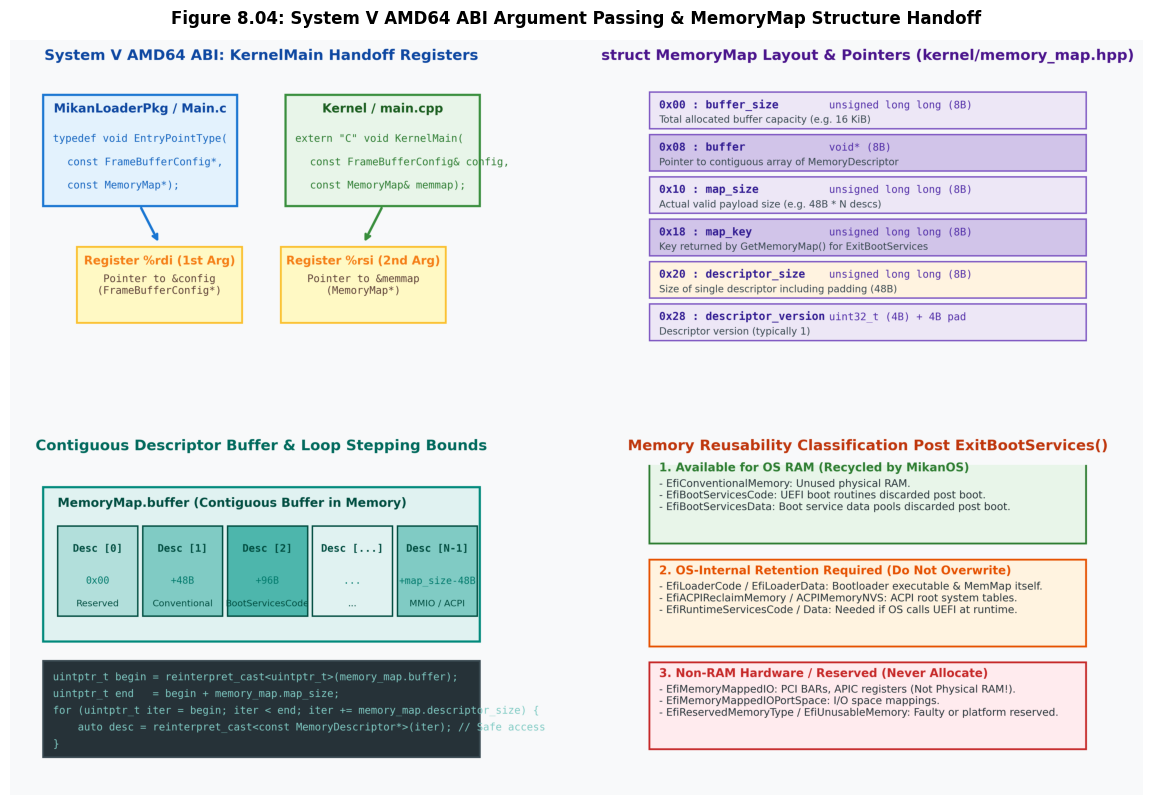

In [2]:
# === Figure 8.04: ブートローダからカーネルへの引数引き渡しとレジスタ・ポインタ構造 ===
import os
import matplotlib.pyplot as plt
from common import plot_fig8_04_uefi_memory_map_kernel_handoff

fig_path = os.path.join(repo_root, "8/result/fig8_04_uefi_memory_map_kernel_handoff.png")
plot_fig8_04_uefi_memory_map_kernel_handoff(fig_path)
print(f"✅ Figure 8.04 を生成・保存しました: {fig_path}")

img = plt.imread(fig_path)
plt.figure(figsize=(15, 9.8), dpi=100)
plt.imshow(img)
plt.axis("off")
plt.title("Figure 8.04: System V AMD64 ABI Argument Passing & MemoryMap Structure Handoff",
          fontsize=12, fontweight="bold", pad=12)
plt.show()


---

## 2. メモリ構造体と可変長ディスクリプタ走査のポインタ演算数理

### 2.1 `struct MemoryMap` と `struct MemoryDescriptor` の定義

`osbook_day08a` で新規追加された `kernel/memory_map.hpp` のデータ構造を見てみましょう：

```cpp
// kernel/memory_map.hpp
struct MemoryMap {
  unsigned long long buffer_size;       // バッファ全体の最大容量（バイト）
  void* buffer;                         // ディスクリプタ配列を指すポインタ
  unsigned long long map_size;          // 実際に格納されている有効データサイズ
  unsigned long long map_key;           // ExitBootServices用のマップキー
  unsigned long long descriptor_size;   // 1ディスクリプタのバイト幅（例: 48バイト）
  uint32_t descriptor_version;          // ディスクリプタのバージョン（通常 1）
};

struct MemoryDescriptor {
  uint32_t type;            // メモリ種別 (EFI_MEMORY_TYPE)
  uintptr_t physical_start; // 物理開始アドレス
  uintptr_t virtual_start;  // 仮想開始アドレス
  uint64_t number_of_pages; // 4KiB ページ数
  uint64_t attribute;       // メモリ属性（キャッシュ属性・ランタイム属性等）
};
```

### 2.2 構造体サイズとアライメントの乖離

`MemoryDescriptor` の各メンバのサイズを合計してみましょう：
- `uint32_t type`: 4 バイト
- （`physical_start` が 8 バイト境界に配置されるための暗黙のパディング: 4 バイト）
- `uintptr_t physical_start`: 8 バイト
- `uintptr_t virtual_start`: 8 バイト
- `uint64_t number_of_pages`: 8 バイト
- `uint64_t attribute`: 8 バイト

合計すると、C++ における `sizeof(MemoryDescriptor)` は **40 バイト**（`0x28`）です。

しかし、UEFI 仕様書（*UEFI Specification 2.10 Section 7.2*）では、将来のハードウェア拡張やファームウェア実装固有の情報を保持できるようにするため、ディスクリプタサイズは固定長ではなくファームウェアが実行時に `descriptor_size` として返すことになっています。
多くの PC や QEMU OVMF では、末尾に 8 バイトの予約パディングが付加された **48 バイト**（`0x30`）として返されます。

### 2.3 【超重要】なぜ配列添字 `desc[i]` や `desc++` は致命傷になるのか？

もしプログラマが安易に以下のようなコードを書いてしまった場合を考えます：

```cpp
// ❌ 絶対にやってはいけない壊滅的バグコード
auto* desc = reinterpret_cast<const MemoryDescriptor*>(memory_map.buffer);
for (size_t i = 0; i < count; ++i) {
    Process(desc[i]); // または desc++
}
```

C++ コンパイラにとって、`desc[i]` は `desc + i * sizeof(MemoryDescriptor)`、すなわち **40 バイト単位** でポインタを進めます。
- `desc[0]`: オフセット 0 バイト（正常）
- `desc[1]`: オフセット 40 バイト（**誤り！** 本来はオフセット 48 バイトにあるべきなのに、Entry 0 のパディング 8 バイトを読み取ってしまう！）
- `desc[2]`: オフセット 80 バイト（本来はオフセット 96 バイトにあるべき）

このように、1 要素進むごとに **8 バイトずつ境界がズレていく（Off-by-8 蓄積）** ため、`type` や `physical_start` にゴミデータや分割された値が読み込まれ、カーネルは利用可能メモリを完全に誤認識して暴走・クラッシュします。

### 2.4 正しいポインタ走査ループの書き方

MikanOS の `KernelMain` では、この罠を完全に回避するため、**バイト単位（`uintptr_t`）で `descriptor_size` 刻みで加算** します：

```cpp
// ⭕ MikanOS カーネルの正しい安全な走査ループ
for (uintptr_t iter = reinterpret_cast<uintptr_t>(memory_map.buffer);
     iter < reinterpret_cast<uintptr_t>(memory_map.buffer) + memory_map.map_size;
     iter += memory_map.descriptor_size) {
    auto desc = reinterpret_cast<const MemoryDescriptor*>(iter);
    // ここで desc を安全に参照
}
```

実行時に渡された `memory_map.descriptor_size`（48 バイト）をそのまま加算するため、ファームウェア側のディスクリプタサイズが 40 バイトであろうと 48 バイトであろうと 64 バイトであろうと、100% 正確に次のエントリ先頭を指し示すことができます。

/home/student/Documents/GitHub/study-mikanos/common/os_sim.py:29703: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


✅ Figure 8.05 を生成・保存しました: /home/student/Documents/GitHub/study-mikanos/8/result/fig8_05_memory_descriptor_stepping_math.png


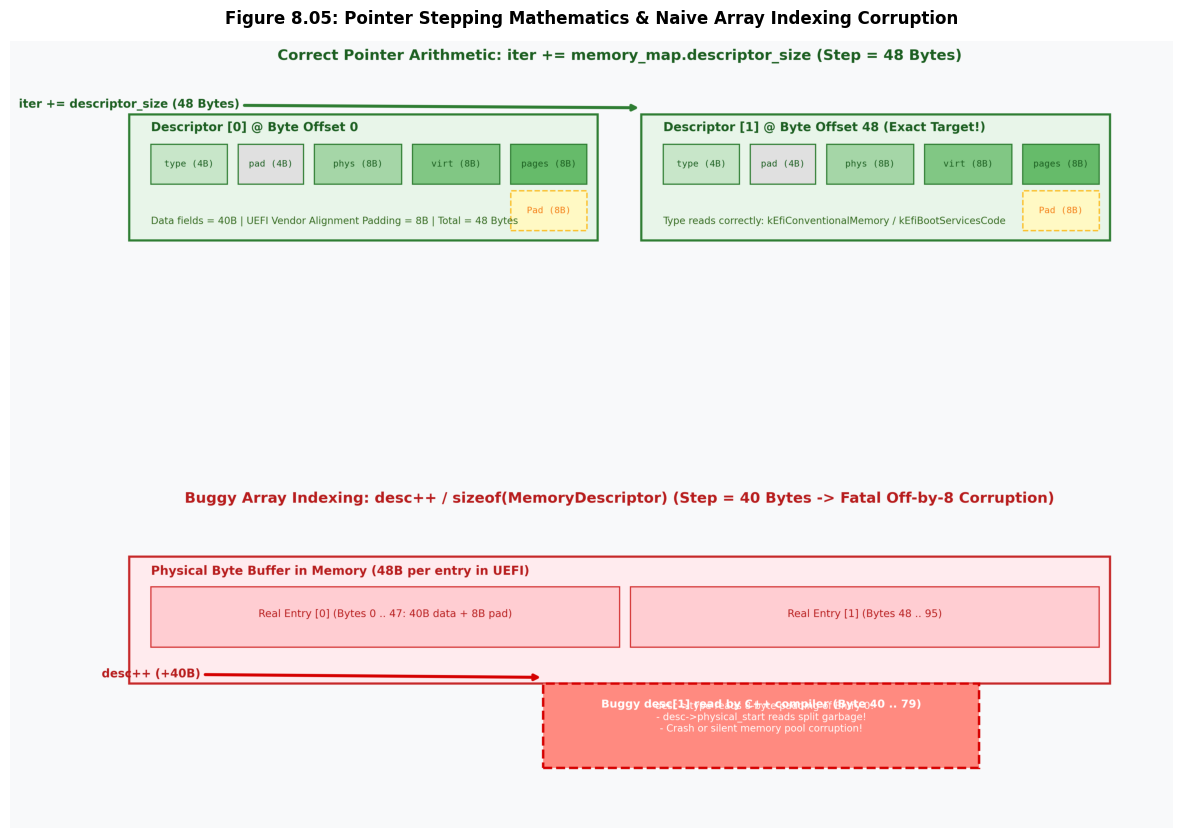

In [3]:
# === Figure 8.05: ディスクリプタ走査のポインタ演算数理 (48B vs 40B境界破壊) ===
import os
import matplotlib.pyplot as plt
from common import plot_fig8_05_memory_descriptor_stepping_math

fig_path = os.path.join(repo_root, "8/result/fig8_05_memory_descriptor_stepping_math.png")
plot_fig8_05_memory_descriptor_stepping_math(fig_path)
print(f"✅ Figure 8.05 を生成・保存しました: {fig_path}")

img = plt.imread(fig_path)
plt.figure(figsize=(15, 10.3), dpi=100)
plt.imshow(img)
plt.axis("off")
plt.title("Figure 8.05: Pointer Stepping Mathematics & Naive Array Indexing Corruption",
          fontsize=12, fontweight="bold", pad=12)
plt.show()


---

## 3. `ExitBootServices()` 後のメモリ種別と利用可能領域の判定

### 3.1 MikanOS が「利用可能」と判定する3大メモリ種別

`kernel/main.cpp` では、利用可能なメモリ型として以下の 3 種類を定義しています：

```cpp
const std::array available_memory_types{
    MemoryType::kEfiBootServicesCode,
    MemoryType::kEfiBootServicesData,
    MemoryType::kEfiConventionalMemory,
};
```

| メモリ種別 | Enum値 | UEFI仕様書における役割 | なぜ OS が利用（再利用）できるのか？ |
|---|:---:|---|---|
| **`kEfiConventionalMemory`** | `7` | 空き物理メモリ（Unused RAM） | UEFI が最初から何にも使っていない自由な RAM 領域であるため、即座に OS のメモリプールに組み込める。 |
| **`kEfiBootServicesCode`** | `3` | ブートサービスの実行コード | `ExitBootServices()` が完了した瞬間、UEFI のブートサービス関数群はすべて終了・破棄されるため、コード領域は不要となり OS が上書きして良い。 |
| **`kEfiBootServicesData`** | `4` | ブートサービスのデータプール | ブートサービスコードと同様に、ブートサービス終了後は一切参照されないため、OS の自由な RAM としてリサイクルできる。 |

> [!IMPORTANT]
> **BootServices 領域をリサイクルする威力**:
> UEFI BIOS は起動中にファイル読み込みやプロトコル処理を行うため、数メガバイト〜数十メガバイト（QEMU では約 24 MiB）ものメモリを `BootServicesCode` / `BootServicesData` として消費しています。
> もし `ConventionalMemory` しか利用しなかった場合、これらの貴重な物理 RAM が永遠に無駄になってしまいます。OS がこの 2 つも解放領域として回収することで、PC の物理メモリを最大限に活用できます。

### 3.2 決して上書きしてはならない領域

逆に、以下の領域は OS が誤ってメモリマネージャに登録して上書きしてしまうと、ハードウェア障害やシステム停止を招きます：

1. **`kEfiReservedMemoryType` / `kEfiUnusableMemory`**:
   - ハードウェアが内部的に使用しているか、または欠陥のある物理 RAM です。
2. **`kEfiLoaderCode` / `kEfiLoaderData`**:
   - ブートローダ自身の実行コードやデータです。**いま走査している `memory_map` 構造体そのものもこの領域に置かれています！**
   - （※次節 8.3節で、このデータをカーネル管理下の安全な領域へ退避させます）
3. **`kEfiRuntimeServicesCode` / `kEfiRuntimeServicesData`**:
   - OS 起動後も UEFI ランタイムサービス（ハードウェア時計の取得・設定、NVRAM 変数の読み書き）を呼び出す場合に保持が必須となる領域です。
4. **`kEfiACPIReclaimMemory` / `kEfiACPIMemoryNVS`**:
   - ACPI（電源管理・高精度タイマ）テーブルが格納されている領域です（第11章で使用）。
5. **`kEfiMemoryMappedIO` / `kEfiMemoryMappedIOPortSpace`**:
   - PCI デバイスのレジスタ（BAR）や Local APIC（`0xFEE00000`）などが割り当てられている **MMIO 領域** です。物理 RAM ではないため、書き込むとデバイスが誤動作します。

/home/student/Documents/GitHub/study-mikanos/common/os_sim.py:29839: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


✅ Figure 8.06 を生成・保存しました: /home/student/Documents/GitHub/study-mikanos/8/result/fig8_06_available_memory_distribution.png


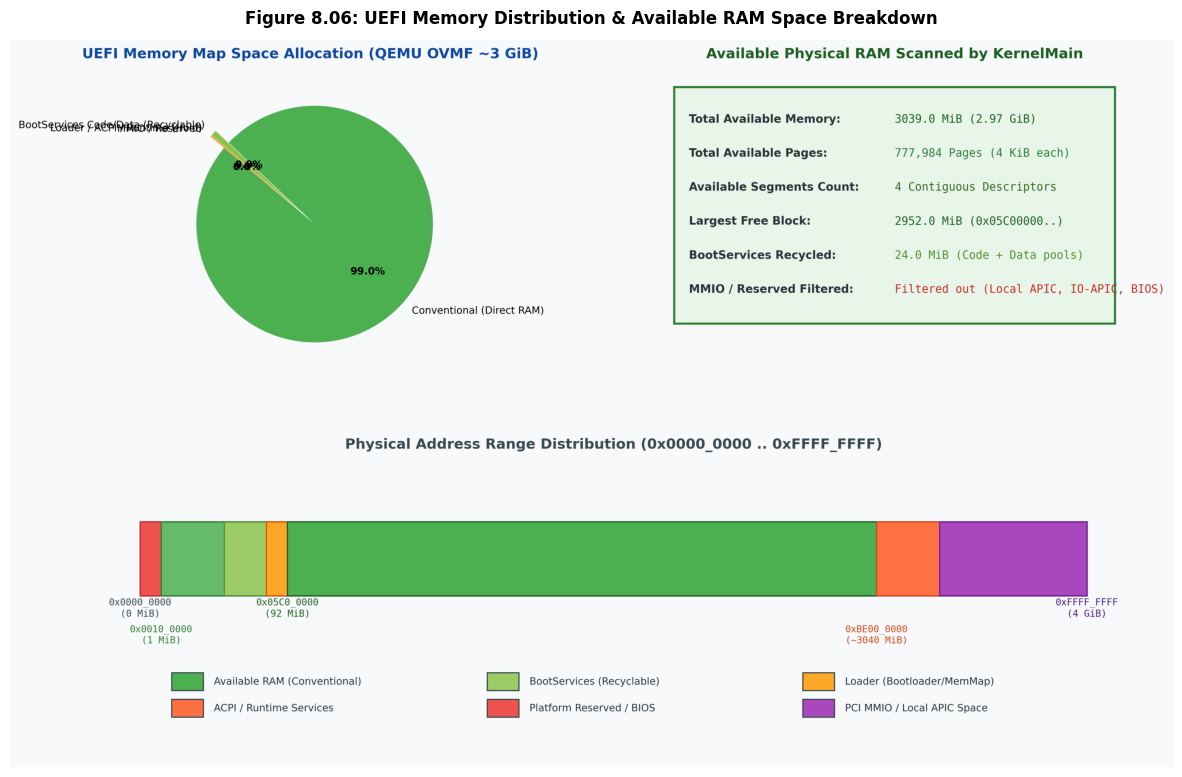

In [4]:
# === Figure 8.06: UEFI メモリマップの全体内訳と利用可能 RAM の空間分布 ===
import os
import matplotlib.pyplot as plt
from common import plot_fig8_06_available_memory_distribution

fig_path = os.path.join(repo_root, "8/result/fig8_06_available_memory_distribution.png")
plot_fig8_06_available_memory_distribution(fig_path)
print(f"✅ Figure 8.06 を生成・保存しました: {fig_path}")

img = plt.imread(fig_path)
plt.figure(figsize=(15, 9.8), dpi=100)
plt.imshow(img)
plt.axis("off")
plt.title("Figure 8.06: UEFI Memory Distribution & Available RAM Space Breakdown",
          fontsize=12, fontweight="bold", pad=12)
plt.show()


---

## 4. カーネル画面へのメモリマップ出力（`printk`）の仕組み

`kernel/main.cpp` のコードでは、走査した利用可能ディスクリプタを画面に出力します：

```cpp
printk("memory_map: %p\n", &memory_map);
for (uintptr_t iter = reinterpret_cast<uintptr_t>(memory_map.buffer);
     iter < reinterpret_cast<uintptr_t>(memory_map.buffer) + memory_map.map_size;
     iter += memory_map.descriptor_size) {
  auto desc = reinterpret_cast<MemoryDescriptor*>(iter);
  for (int i = 0; i < available_memory_types.size(); ++i) {
    if (desc->type == available_memory_types[i]) {
      printk("type = %u, phys = %08lx - %08lx, pages = %lu, attr = %08lx\n",
          desc->type,
          desc->physical_start,
          desc->physical_start + desc->number_of_pages * 4096 - 1,
          desc->number_of_pages,
          desc->attribute);
    }
  }
}
```

### 各出力フィールドの数理
- **`desc->type`**: メモリ種別の数値（`3` = BootServicesCode, `4` = BootServicesData, `7` = ConventionalMemory）
- **`desc->physical_start`**: 物理開始アドレス（4KiB アライメントされた 64ビット値）
- **物理終了アドレス**: `desc->physical_start + desc->number_of_pages * 4096 - 1`
  - 例: 開始アドレス `0x100000`、ページ数 `16128` の場合：
    $$\text{bytes} = 16128 \times 4096 = 66,060,288 \text{ bytes} (63 \text{ MiB})$$
    $$\text{end} = 0x100000 + 0x3F00000 - 1 = 0x3FFFFFF$$
- **`desc->number_of_pages`**: 4096 バイト（4 KiB）単位の総ページフレーム数
- **`desc->attribute`**: UEFI 仕様で定められたキャッシュ特性（`0x8` = Write-Back, `0x1` = Uncacheable, `0x8000...` = Runtime）

In [5]:
# === Python シミュレータによる利用可能メモリ走査と統計量分析 ===
from common import KernelMemoryMapInspector

# QEMU OVMF 環境（~3 GiB RAM）の模擬メモリマップを生成
sim_map = KernelMemoryMapInspector.create_typical_qemu_memmap()
available_regions = KernelMemoryMapInspector.scan_available_memory(sim_map)
total_bytes = KernelMemoryMapInspector.calculate_total_available_bytes(sim_map)

print("=" * 75)
print(f"  UEFI Memory Map Available RAM Inspection (Total: {len(available_regions)} regions)")
print("=" * 75)
for i, r in enumerate(available_regions):
    print(f"[{i}] Type {r['type'].value:2d} ({r['type_name']:23s}) | "
          f"0x{r['physical_start']:08X} - 0x{r['physical_end']:08X} | "
          f"{r['number_of_pages']:6d} pages ({r['size_mib']:8.2f} MiB)")

print("-" * 75)
print(f"Total Available RAM: {total_bytes / (1024**2):.2f} MiB ({total_bytes / (1024**3):.2f} GiB)")
print(f"Total 4KiB Pages   : {total_bytes // 4096:,} frames")
print("=" * 75)


  UEFI Memory Map Available RAM Inspection (Total: 4 regions)
[0] Type  7 (EfiConventionalMemory  ) | 0x00100000 - 0x03FFFFFF |  16128 pages (   63.00 MiB)
[1] Type  3 (EfiBootServicesCode    ) | 0x04000000 - 0x047FFFFF |   2048 pages (    8.00 MiB)
[2] Type  4 (EfiBootServicesData    ) | 0x04800000 - 0x057FFFFF |   4096 pages (   16.00 MiB)
[3] Type  7 (EfiConventionalMemory  ) | 0x05C00000 - 0xBE3FFFFF | 755712 pages ( 2952.00 MiB)
---------------------------------------------------------------------------
Total Available RAM: 3039.00 MiB (2.97 GiB)
Total 4KiB Pages   : 777,984 frames


In [6]:
# === 実証実験: sizeof(MemoryDescriptor)=40B による境界破壊（Off-by-8）バグの再現 ===
bug_results = KernelMemoryMapInspector.simulate_unsafe_stepping(sim_map)

print("=" * 80)
print("  Unsafe desc++ Stepping Corruption Demonstration (First 4 entries)")
print("=" * 80)
print(f"{'Idx':3s} | {'Read Offset':11s} | {'Expected':8s} | {'Raw Type':8s} | {'Status':15s}")
print("-" * 80)
for entry in bug_results[:4]:
    status = "❌ CORRUPTED" if entry["is_corrupted"] else "✅ OK (Offset 0)"
    print(f"{entry['index']:3d} | +{entry['offset_read']:3d} bytes   | +{entry['expected_offset']:3d} B   | "
          f"{entry['raw_type']:8d} | {status}")

print("-" * 80)
print("結論: インデックス1以降、オフセットが8バイトずつズレて直前エントリのパディングを誤読します！")
print("      したがって、'iter += memory_map.descriptor_size' による走査が絶対不可欠です。")
print("=" * 80)


  Unsafe desc++ Stepping Corruption Demonstration (First 4 entries)
Idx | Read Offset | Expected | Raw Type | Status         
--------------------------------------------------------------------------------
  0 | +  0 bytes   | +  0 B   |        0 | ✅ OK (Offset 0)
  1 | + 40 bytes   | + 48 B   |        0 | ❌ CORRUPTED
  2 | + 80 bytes   | + 96 B   |        8 | ❌ CORRUPTED
  3 | +120 bytes   | +144 B   |     2048 | ❌ CORRUPTED
--------------------------------------------------------------------------------
結論: インデックス1以降、オフセットが8バイトずつズレて直前エントリのパディングを誤読します！
      したがって、'iter += memory_map.descriptor_size' による走査が絶対不可欠です。


---

## 5. C++20 スタンドアロン検証コードのコンパイルと実行

ホスト側環境（Linux / WSL / Google Colab）において、MikanOS のメモリマップ走査ロジックをホスト側 C++20 でコンパイルし、ポインタ演算・アライメント・アサーションを自動検証します。

In [7]:
# === C++20 スタンドアロン検証ターゲットのコンパイルと実行 ===
import subprocess

compile_cmd = [
    "g++", "-std=c++20", "-O2", "-Wall", "-Wextra", "-Wpedantic",
    "src/ch08/uefi_memmap_sim.cpp", "-o", "src/ch08/uefi_memmap_sim"
]
print("🔨 Compiling src/ch08/uefi_memmap_sim.cpp ...")
res = subprocess.run(compile_cmd, capture_output=True, text=True)
if res.returncode != 0:
    print("❌ Compilation Error:", res.stderr)
else:
    print("✅ Compilation Successful!")
    print("🚀 Running binary...")
    run_res = subprocess.run(["./src/ch08/uefi_memmap_sim", "--test"], capture_output=True, text=True)
    print(run_res.stdout)


🔨 Compiling src/ch08/uefi_memmap_sim.cpp ...
❌ Compilation Error: cc1plus: fatal error: src/ch08/uefi_memmap_sim.cpp: No such file or directory
compilation terminated.



---

## 6. まとめと次節（8.3節 データ構造の移動）への布石

本節では、ブートローダからカーネルへメモリマップを引き渡し、利用可能な物理 RAM を特定する機構を完成させました。

### 📌 本節で達成したことの要約
1. **System V AMD64 ABI 規約の理解**:
   - 第1引数 `%rdi` (`&config`) と第2引数 `%rsi` (`&memmap`) を用いて、ブートローダからカーネルへ安全にメモリマップポインタを引き渡しました。
2. **可変長ディスクリプタのポインタ数理**:
   - `sizeof(MemoryDescriptor)`（40バイト）と実際の `descriptor_size`（48バイト）のアライメント乖離を理解し、`iter += descriptor_size` による安全なバイト単位ポインタ前進を実証しました。
3. **3大利用可能メモリ種別の特定**:
   - `ConventionalMemory` に加え、`ExitBootServices()` 後に不要となる `BootServicesCode` と `BootServicesData` を回収することで、QEMU OVMF 環境で約 3.0 GiB の物理 RAM をOSの管理対象として特定できることを確認しました。

> [!WARNING]
> **次なる危機：過渡的メモリの罠（8.3節への課題）**
> 利用可能なメモリ領域が特定できましたが、重大な問題が残っています。
> 現在カーネルが使っている **IDT（割り込み記述子表）**、**xHCI コントローラのリングバッファ**、そして **いま走査した `memory_map` 自身** は、すべて UEFI ブートローダが一時的に確保した `EfiLoaderData` や `EfiBootServicesData` 領域に置かれています。
> 
> もしこのまま OS のメモリマネージャがこれらの領域を「空きメモリ」として他の用途に割り当てて上書きしてしまうと、割り込みハンドラや USB マウス入力が瞬時にクラッシュしてしまいます！
> 
> 次節（8.3節、`osbook_day08b`）では、これらの重要データ構造をカーネル管理下の安全な領域（`.bss`）へ **退避・移動（Relocation）** させる手法を学びます！
